# 02 · One-step DNS by maximum likelihood (Kalman filter), USD

The same dynamic Nelson–Siegel model as notebook 01, but estimated in one step
(README §6.3). The VAR matrix A, the shock covariance Q, the 17
measurement-error variances and optionally λ are chosen to maximise the
Kalman-filter likelihood of the observed yields. The factor means μ are
fixed at the sample mean of the month-by-month OLS factors (README §6.3):
estimated, μ is barely identified, and it was the main source of the
mean-reversion bias found below. The filter is written
from scratch (`src/yck/model/kalman.py`) and checked against statsmodels.

Same sample as notebook 01: estimation from **1985-01**, forecast origins
from **2000-01**. Parameters are re-estimated every 12 months and
forecasts start from **filtered** states, so nothing uses data after the
origin.

**Estimation.** EM, then L-BFGS-B with the exact score (Fisher's identity),
6 starting points per fit, and a 1 bp floor on each maturity's noise sd (§2
explains why). Each refit is independent, so the backtests run in parallel
and are cached: `python -m yck backtest --ccy USD EUR GBP --all` runs every
backtest in the project in ~1.5 min from scratch, seconds when cached.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from yck.model.dns import fit_factors, fit_rmse_bp, DL_LAMBDA, ns_loadings
from yck.model.statespace_dns import fit_dns_mle
from yck.eval.backtest import dns_two_step_forecasts, random_walk_forecasts, rmse_table
from yck.eval.grid import ensure_results

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "data/results"
EST_START, FIRST_ORIGIN, H = "1985-01-31", "2000-01-31", (1, 6, 12)
y = pd.read_parquet(ROOT / "data/processed/curves_USD.parquet").loc[EST_START:]
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
print(f"{len(y)} months, {y.index[0]:%Y-%m} to {y.index[-1]:%Y-%m}")

502 months, 1985-01 to 2026-10


## 1. Full-sample estimates: fixed vs estimated λ

λ sets where the curvature loading peaks. Diebold–Li fix it at 0.0609 (a peak
at about 30 months). Estimating it adds one parameter, so BIC is the fair
comparison.

In [2]:
fits = {
    "λ fixed (0.0609)": fit_dns_mle(y, n_starts=6),
    "λ estimated": fit_dns_mle(y, estimate_lambda=True, n_starts=6),
    "λ estimated, no floor": fit_dns_mle(y, estimate_lambda=True, h_floor_bp=None, n_starts=6),
}
summary = pd.DataFrame({
    name: {"log-likelihood": f.loglik, "parameters": f.n_params, "BIC": f.bic, "λ": f.params.lam,
           "curvature peak (months)": 1.7933 / f.params.lam,
           "max |eig(A)|": np.max(np.abs(np.linalg.eigvals(f.params.A))),
           "maturities at floor": int(np.sum(f.params.h <= 1.0001e-4)), "seconds": f.seconds}
    for name, f in fits.items()}).T
summary.round(4)

,log-likelihood,parameters,BIC,λ,curvature peak (months),max |eig(A)|,maturities at floor,seconds
λ fixed (0.0609),13283.9879,32.0,-26278.3178,0.0609,29.4466,0.9932,6.0,0.3627
λ estimated,15393.8725,33.0,-30489.0352,0.0392,45.7089,0.9939,6.0,0.3823
"λ estimated, no floor",15929.4819,33.0,-31560.2539,0.0415,43.2609,0.9938,5.0,0.7401


In [3]:
for name, f in fits.items():
    print(name)
    print("  mu =", f.params.mu.round(2))
    print("  A  =", np.array2string(f.params.A.round(3), prefix="       "))
    print("  sd(factor shocks), bp:", (100 * np.sqrt(np.diag(f.params.Q))).round(1))

λ fixed (0.0609)
  mu = [ 5.4  -1.92 -2.09]
  A  = [[ 0.988  0.001  0.018]
        [-0.022  0.943  0.043]
        [ 0.023  0.026  0.933]]
  sd(factor shocks), bp: [32.2 36.7 72.8]
λ estimated
  mu = [ 5.4  -1.92 -2.09]
  A  = [[ 0.984  0.007  0.021]
        [-0.013  0.969  0.019]
        [ 0.037  0.014  0.925]]
  sd(factor shocks), bp: [35.3 39.9 86.4]
λ estimated, no floor
  mu = [ 5.4  -1.92 -2.09]
  A  = [[ 0.982  0.005  0.024]
        [-0.013  0.967  0.02 ]
        [ 0.04   0.018  0.92 ]]
  sd(factor shocks), bp: [36.  39.5 90.4]


## 2. Measurement error by maturity, and why there is a 1 bp floor

The one-step model estimates a separate noise variance for each maturity, so
the filter trusts precise maturities more. **Without a floor**, some
maturities come out at ~0.01 bp. GSW yields are points on a smooth fitted
Svensson curve, not raw bond prices, so three factors can match a few of
them almost exactly. That has two consequences:

- The likelihood becomes extremely badly conditioned: steep in some
  directions, flat in others. Quasi-Newton methods then stop with large
  gradients (up to ~3,500 in our refits), and different starts end at
  scattered local maxima.
- It is not credible as measurement error: no real yield is measured to
  0.01 bp.

With a floor of **1 bp**, every start converges (gradient < 0.02) and
starts land on one or two reproducible optima, so 6 starts find the best.
The log-likelihoods with and without the floor are not comparable (the
unfloored model is less restricted), which is why the table above lists both.

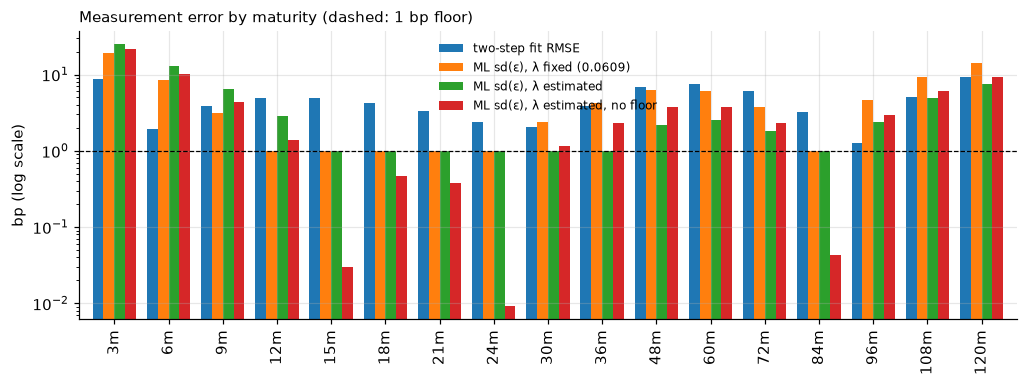

In [4]:
f2 = fit_factors(y)
noise = pd.DataFrame({"two-step fit RMSE": fit_rmse_bp(y, f2)})
for name, f in fits.items():
    noise[f"ML sd(ε), {name}"] = 100 * np.sqrt(f.params.h)
ax = noise.plot.bar(figsize=(11, 3.4), width=0.8, logy=True)
ax.axhline(1.0, color="k", lw=0.8, ls="--")
ax.set_ylabel("bp (log scale)"); ax.set_title("Measurement error by maturity (dashed: 1 bp floor)", loc="left", fontsize=10)
ax.legend(fontsize=8, frameon=False); plt.show()


## 3. Factors: filtered (one-step) vs two-step

Filtered factors use data up to t only. They should look very like the
month-by-month OLS factors, because the yields are precise; the filter mainly
adds smoothing where the cross-section is noisy.

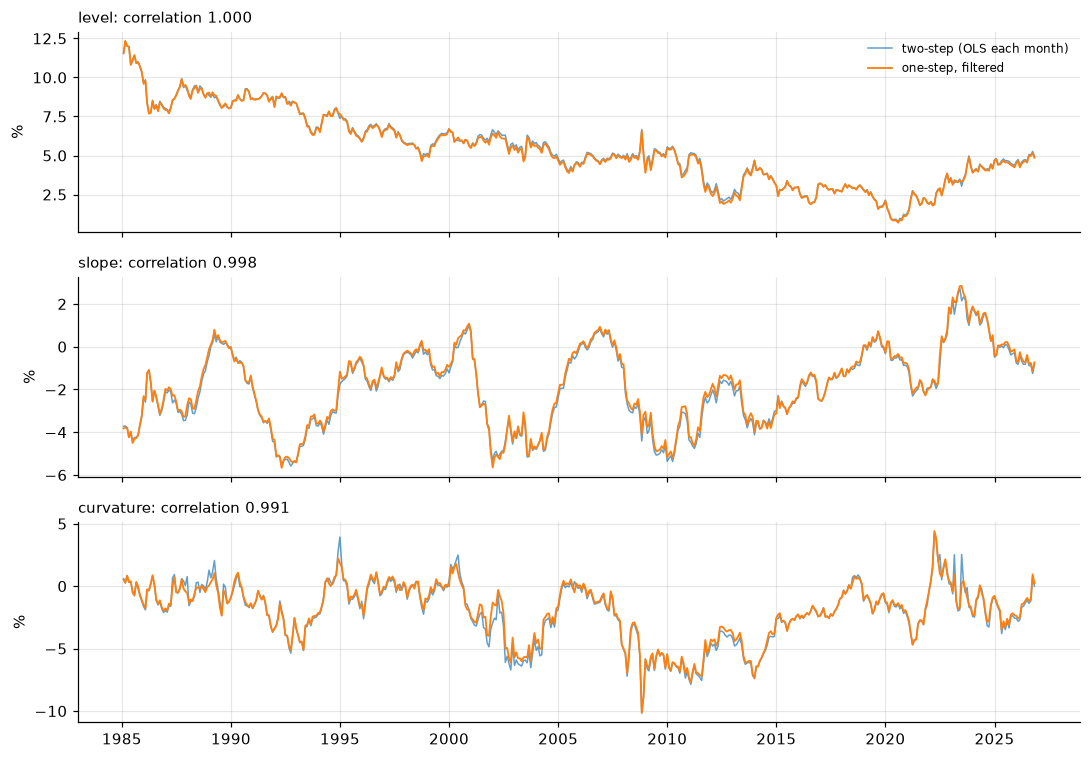

In [5]:
best = fits["λ fixed (0.0609)"]
ff = best.filtered_factors(y)
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, c in zip(axes, ff.columns):
    ax.plot(f2[c], lw=1, alpha=0.7, label="two-step (OLS each month)")
    ax.plot(ff[c], lw=1.2, label="one-step, filtered")
    ax.set_title(f"{c}: correlation {ff[c].corr(f2[c]):.3f}", loc="left", fontsize=10); ax.set_ylabel("%")
axes[0].legend(fontsize=8, frameon=False); fig.tight_layout()

## 4. Out-of-sample forecasts vs the random walk

The backtest refits the model 27 times per variant. Forecasts are written to
`data/results/` (git-ignored) by `python -m yck backtest --all`. If they are
missing, this cell runs the same grid once (`ensure_results`).
The two-step forecasts from notebook 01 are recomputed here, since they take
under a second.

In [6]:
# Kalman backtests come from data/results/. If any are missing, the whole standard
# grid runs once, in one longest-first pool (`python -m yck backtest --all`, ~1.5 min).
ensure_results(["USD"], ROOT / "data", ROOT / "config/data_sources.yaml")
kalman_fc = lambda tag: {h: pd.read_parquet(RESULTS / f"fc_USD_kalman_{tag}_h{h}.parquet") for h in H}

models = {
    "two-step AR(1)": dns_two_step_forecasts(y, H, FIRST_ORIGIN, kind="ar1"),
    "two-step VAR(1)": dns_two_step_forecasts(y, H, FIRST_ORIGIN, kind="var1"),
    "Kalman, λ fixed": kalman_fc("lamfixed"),
    "Kalman, λ estimated": kalman_fc("lamest"),
}
rw = random_walk_forecasts(y, H, FIRST_ORIGIN)
SHOW = ["3m", "12m", "24m", "60m", "120m"]
tables = {h: rmse_table({**{n: m[h] for n, m in models.items()}, "RW": rw[h]}, y) for h in H}
ratio = pd.concat({f"h={h}": tables[h][list(models)].div(tables[h]["RW"], axis=0).loc[SHOW] for h in H})
ratio.round(2).join(pd.concat({f"h={h}": tables[h][["RW"]].loc[SHOW] for h in H}).round(1)
                    .rename(columns={"RW": "RW RMSE (bp)"}))

two-step AR(1)  two-step VAR(1)  Kalman, λ fixed  \
h=1  3m              1.08             0.86             0.97   
     12m             1.08             0.98             0.98   
     24m             1.05             1.00             1.01   
     60m             1.14             1.08             1.06   
     120m            1.04             1.05             1.14   
h=6  3m              1.09             0.84             0.86   
     12m             1.14             0.95             0.97   
     24m             1.16             1.01             1.04   
     60m             1.20             1.08             1.10   
     120m            1.08             1.03             1.05   
h=12 3m              1.06             0.88             0.89   
     12m             1.10             0.96             0.98   
     24m             1.15             1.02             1.05   
     60m             1.26             1.12             1.15   
     120m            1.17             1.07             1.10   

           Kalman, λ estimated  RW RMSE (bp)  
h=1  3m                   1.02          23.7  
     12m                  0.99          21.7  
     24m                  1.02          24.6  
     60m                  1.02          26.8  
     120m                 1.07          26.7  
h=6  3m                   0.88          86.5  
     12m                  0.99          80.3  
     24m                  1.04          76.0  
     60m                  1.07          67.0  
     120m                 1.07          60.1  
h=12 3m                   0.92         149.1  
     12m                  0.99         138.9  
     24m                  1.04         123.9  
     60m                  1.12          95.8  
     120m                 1.12          80.2

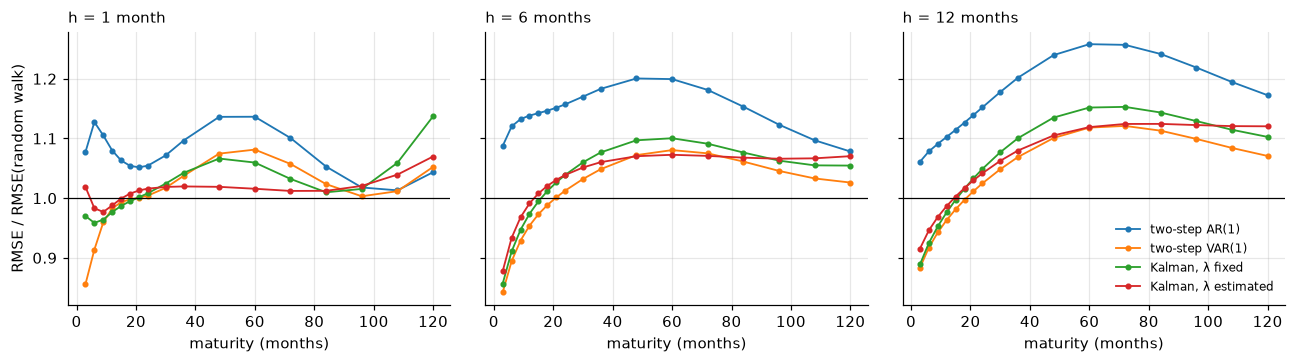

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
mats = [int(c[:-1]) for c in y.columns]
for ax, h in zip(axes, H):
    for n in models:
        ax.plot(mats, tables[h][n] / tables[h]["RW"], marker="o", ms=3, lw=1.2, label=n)
    ax.axhline(1, color="k", lw=0.8)
    ax.set_title(f"h = {h} month" + ("s" if h > 1 else ""), loc="left", fontsize=10)
    ax.set_xlabel("maturity (months)")
axes[0].set_ylabel("RMSE / RMSE(random walk)"); axes[-1].legend(fontsize=8, frameon=False)
fig.tight_layout()

## 5. Is the mean-reversion bias still there?

Notebook 01 found that the two-step forecasts ran too high in 2000–2015,
because they revert to a high historical mean. One-step estimation changes
how the parameters are estimated, but not that mechanism.

In [8]:
h = 12
periods = [("2000", "2007", "2000–07"), ("2008", "2015", "2008–15 (ZLB)"), ("2016", "2026", "2016–")]
err = {n: 100 * (m[h] - y).reindex(rw[h].index) for n, m in {**models, "RW": rw}.items()}
pd.DataFrame({lab: {n: e.loc[a:b, "120m"].mean() for n, e in err.items()} for a, b, lab in periods}).round(0)

,2000–07,2008–15 (ZLB),2016–
two-step AR(1),58.0,80.0,-10.0
two-step VAR(1),47.0,45.0,11.0
"Kalman, λ fixed",51.0,29.0,5.0
"Kalman, λ estimated",56.0,37.0,11.0
RW,20.0,31.0,-22.0


## 6. Parameter stability across re-estimations

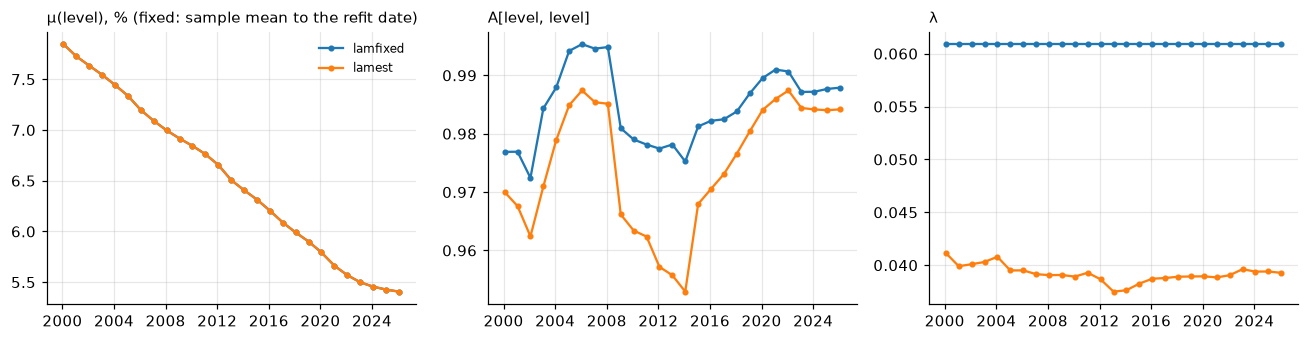

In [9]:
params = {tag: pd.read_csv(RESULTS / f"params_USD_kalman_{tag}.csv", parse_dates=["origin"]).set_index("origin")
          for tag in ("lamfixed", "lamest") if (RESULTS / f"params_USD_kalman_{tag}.csv").exists()}
if params:
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
    for tag, p in params.items():
        for ax, col, title in zip(axes, ["mu0", "A00", "lam"], ["μ(level), % (fixed: sample mean to the refit date)", "A[level, level]", "λ"]):
            ax.plot(p.index, p[col], marker="o", ms=3, label=tag)
            ax.set_title(title, loc="left", fontsize=10)
    axes[0].legend(fontsize=8, frameon=False); fig.tight_layout()

## 7. Takeaways

- **The one-step model fits far better in-sample.** With the 1 bp floor, the
  log-likelihood rises from about 11,170 at the two-step estimates to 13,284
  (λ fixed) and 15,394 (λ estimated, ≈ 0.039, curvature peak at ≈ 46
  months). Filtered factors are almost the same as the two-step ones.
  Fixing μ at the sample mean costs about one log-likelihood point: the data
  say very little about the long-run mean.
- **Out of sample it now matches the two-step VAR(1), not beats it.**
  USD 2000–2026, h = 12, RMSE relative to the random walk: Kalman (λ fixed)
  0.89 / 0.98 / 1.05 / 1.15 / 1.10 (3m … 10y), two-step VAR(1)
  0.88 / 0.96 / 1.02 / 1.12 / 1.07. Both beat the random walk only at the
  short end. With μ estimated the Kalman ratios were 0.91 / 1.00 / 1.07 /
  1.19 / 1.14. Estimating λ improves the likelihood but not the forecasts.
  (The λ-estimated variant fixes μ at the means of the λ = 0.0609 factors,
  so its slope and curvature means are approximate; treat it as a
  robustness check.)
- **Mean reversion is still the main problem.** At h = 12, 10y forecasts
  were 51 bp too high on average in 2000–07 (two-step VAR: 47, random walk:
  20; with μ estimated: 61). The fixed μ is the 1985-to-date average of the
  level factor, 5.4–7.9% across refits, still above the 1–5% that 10y yields
  mostly were after 2000. Any model that reverts to a historical mean pays
  for that in a period of falling rates.
- **Estimation is reliable and fast.** EM plus the exact score, a 1 bp
  noise floor, 6 starts and fixed μ: every refit converges to the same
  optimum from different starts. Without the floor the likelihood is too
  ill-conditioned for reliable maximisation (§2).
- **Implication for the research question.** Better estimation of a
  yields-only model does not fix its forecasting weakness. The question is
  whether *information* does: macro variables (notebook 03) and the market's
  own forwards (README §7.4), judged both in RMSE and in trading P&L (§7.5).
